# Anticipated Anisotropy from solar flares

Requires:
* `SO_PADRE_positions.csv` ephemeris solar orbiter angles
* `sim_struct.sav` simulated anisotropy data

This estimates total number of flares observed by both SoLO STIX and PADRE. 


In [2]:
import numpy as np 
import matplotlib.pyplot as plt
from astropy import units as u
from scipy.io import readsav
import warnings
from astropy.time import Time, TimeDelta
warnings.filterwarnings("ignore")
from astropy.io import ascii
from astropy.timeseries import TimeSeries
import matplotlib.pyplot as plt

import sunpy.map
from astropy.coordinates import SkyCoord
import astropy.units as u

import matplotlib as mpl
from matplotlib.ticker import MultipleLocator

import astropy.units as u

from sunpy.coordinates import HeliocentricEarthEcliptic, get_body_heliographic_stonyhurst, get_horizons_coord
from sunpy.coordinates import frames

from specutils import Spectrum1D

In [37]:
CB_color_cycle = ['#377eb8', '#ff7f00', '#4daf4a',
                  '#f781bf', '#a65628', '#984ea3',
                  '#999999', '#e41a1c', '#dede00']

In [3]:
mission_start = Time("2025-09-15T00:00")
mission_end = mission_start + TimeDelta(1 * u.year)
extended_end = mission_start + TimeDelta(2 * u.year)

In [89]:
so_coords_jpl = get_horizons_coord('Solar Orbiter', {'start': mission_start,'stop': extended_end, 'step': '1d'})

INFO: Obtained JPL HORIZONS location for Solar Orbiter (spacecraft) (-144) [sunpy.coordinates.ephemeris]


In [90]:
earth_coords = get_horizons_coord('Earth-Moon Barycenter', {'start': mission_start,'stop': extended_end, 'step': '1d'})

INFO: Obtained JPL HORIZONS location for Earth-Moon Barycenter (3)       [sunpy.coordinates.ephemeris]


In [91]:
prime_mission_mask = (so_coords_jpl.obstime >= mission_start) & (so_coords_jpl.obstime <= mission_end)
extended_mission_mask = (so_coords_jpl.obstime > mission_end) & (so_coords_jpl.obstime <= extended_end)

In [93]:
so_coords_jpl[0]

<SkyCoord (HeliographicStonyhurst: obstime=2025-09-15T00:00:00.000, rsun=695700.0 km): (lon, lat, radius) in (deg, deg, AU)
    (-89.95045094, -10.41144437, 0.29531215)>

In [ ]:
def coord_to_heexy(coord):
    hee_frame = HeliocentricEarthEcliptic(obstime=coord.obstime)
    coord = coord.transform_to(hee_frame)
    coord.representation_type = 'cartesian'
    return coord.x.to_value('AU'), coord.y.to_value('AU')

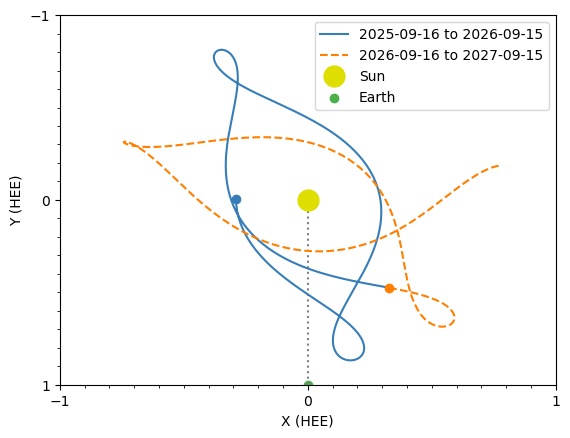

In [173]:
fig = plt.figure()
ax = fig.add_subplot()

ax.set_xlim(-1.0, 1.0)
ax.set_xlabel('X (HEE)')
ax.xaxis.set_major_locator(MultipleLocator(1))
ax.xaxis.set_minor_locator(MultipleLocator(0.1))

ax.set_ylim(1.0, -1.0)
ax.set_ylabel('Y (HEE)')
ax.yaxis.set_major_locator(MultipleLocator(1))
ax.yaxis.set_minor_locator(MultipleLocator(0.1))

ax.plot([0, 0], [0, 2], linestyle='dotted', color='gray')
start_pos_0 = coord_to_heexy(so_coords_jpl[0])
start_pos_1 = coord_to_heexy(so_coords_jpl[1])
#ax.annotate('', xy=start_pos_1, xytext=start_pos_0, arrowprops=dict(arrowstyle='->', color=CB_color_cycle[0]), label='SO Start Position')
label = f'{so_coords_jpl[prime_mission_mask][0].obstime.iso[0:10]} to {so_coords_jpl[prime_mission_mask][-1].obstime.iso[0:10]}'
ax.plot(*coord_to_heexy(so_coords_jpl[prime_mission_mask]), color=CB_color_cycle[0], label=label)
ax.plot(*start_pos_0, 'o', color=CB_color_cycle[0])

label = f'{so_coords_jpl[extended_mission_mask][0].obstime.iso[0:10]} to {so_coords_jpl[extended_mission_mask][-1].obstime.iso[0:10]}'
ax.plot(*coord_to_heexy(so_coords_jpl[extended_mission_mask]), linestyle='dashed', color=CB_color_cycle[1], label=label)

start_pos_0 = coord_to_heexy(so_coords_jpl[extended_mission_mask][0])
ax.plot(*start_pos_0, 'o', color=CB_color_cycle[1])

ax.plot(0, 0, 'o', markersize=15, color=CB_color_cycle[-1], label='Sun')
plt.scatter([0] * u.au, [1] * u.au, marker='o', color=CB_color_cycle[2], label='Earth')
plt.legend()
plt.savefig('solar_orbiter_position.pdf')
plt.show()

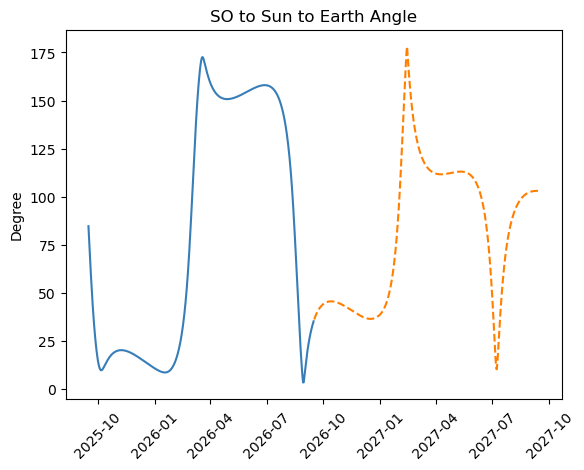

In [175]:
so_sun_earth_angles = so_coords_jpl.separation(earth_coords)

plt.plot(so_coords_jpl[prime_mission_mask].obstime.to_datetime(), so_sun_earth_angles[prime_mission_mask], color=CB_color_cycle[0])
plt.plot(so_coords_jpl[extended_mission_mask].obstime.to_datetime(), so_sun_earth_angles[extended_mission_mask], linestyle='dashed', color=CB_color_cycle[1])
plt.title('SO to Sun to Earth Angle')
plt.ylabel('Degree')
plt.xticks(rotation=45)
plt.savefig('solar_orbiter_angles.pdf')
plt.show()

In [127]:
def interpolate_coords(orig_coords, new_times):
    """Interpolate a set of HeliographicStonyhurst cartesian coordinates as a function of time to a new set of times."""
    orig_ts = (orig_coords.obstime - new_times.min()).to('s').value
    new_ts = (new_times - new_times.min()).to('s').value
    interp_x = np.interp(new_ts, orig_ts, orig_coords.cartesian.x.value) * orig_coords.cartesian.x.unit
    interp_y = np.interp(new_ts, orig_ts, orig_coords.cartesian.y.value) * orig_coords.cartesian.y.unit
    interp_z = np.interp(new_ts, orig_ts, orig_coords.cartesian.z.value) * orig_coords.cartesian.z.unit
    return SkyCoord(interp_x, interp_y, interp_z, frame='heliographic_stonyhurst', representation_type='cartesian', obstime=new_times)

In [139]:
num_flares = 2000000
flare_hpc_lat = np.random.random(num_flares) * 60 * u.deg - 30 * u.deg
flare_hpc_lon = (np.random.random(num_flares)*360) * u.deg
flare_times = TimeDelta(np.random.random(num_flares) * (extended_end - mission_start).to('s')) + mission_start

flare_coords = SkyCoord(flare_hpc_lon, flare_hpc_lat, frame='heliographic_stonyhurst', obstime=flare_times)
prime_flare_mask = (flare_coords.obstime >= mission_start) & (flare_coords.obstime <= mission_end)
extended_flare_mask = (flare_coords.obstime > mission_end) & (flare_coords.obstime <= extended_end)

In [140]:
interp_so_coords = interpolate_coords(so_coords_jpl, flare_times)
interp_earth_coords = interpolate_coords(earth_coords, flare_times)

Prime Mission

In [150]:
hpc_frame = frames.Helioprojective(observer='earth', obstime=flare_coords.obstime[prime_flare_mask])
hpc_flare_coords = flare_coords[prime_flare_mask].transform_to(hpc_frame)
print(f"Percent of flare visible from Earth: {np.sum(hpc_flare_coords.is_visible()) / len(hpc_flare_coords) * 100}%")

hpc_so_frame = frames.Helioprojective(observer=interp_so_coords[prime_flare_mask], obstime=flare_coords.obstime[prime_flare_mask])
hpc_so_flare_coords = flare_coords[prime_flare_mask].transform_to(hpc_so_frame)
#print(f"Percent of flare visible from SO: {np.sum(hpc_so_flare_coords.is_visible()) / len(hpc_so_flare_coords) * 100}%")

visible_both = hpc_so_flare_coords.is_visible() * hpc_flare_coords.is_visible()
print(f"Percent of events visible by both {np.sum(visible_both) / len(visible_both) * 100}%")

Percent of flare visible from Earth: 49.787864173159555%
Percent of events visible by both 27.50566411145094%


Extended Mission

In [142]:
#hpc_frame = frames.Helioprojective(observer='earth', obstime=flare_coords.obstime[extended_flare_mask])
#hpc_flare_coords = flare_coords[extended_flare_mask].transform_to(hpc_frame)
#print(f"Percent of flare visible from Earth: {np.sum(hpc_flare_coords.is_visible()) / len(hpc_flare_coords) * 100}%")

#hpc_so_frame = frames.Helioprojective(observer=interp_so_coords[extended_flare_mask], obstime=flare_coords.obstime[extended_flare_mask])
#hpc_so_flare_coords = flare_coords[extended_flare_mask].transform_to(hpc_so_frame)
#print(f"Percent of flare visible from SO: {np.sum(hpc_so_flare_coords.is_visible()) / len(hpc_so_flare_coords) * 100}%")

#visible_both = hpc_so_flare_coords.is_visible() * hpc_flare_coords.is_visible()
#print(f"Percent of events visible by both {np.sum(visible_both) / len(visible_both) * 100}%")

I would expect to see more flares by both observatories during the extended mission because Solo spends less time behind the Earth.

In [143]:
def is_visible_by_both(coords, observer1, observer2):
    hpc_frame1 = frames.Helioprojective(observer=observer1, obstime=coords.obstime)
    hpc1_coords = coords.transform_to(hpc_frame1)
    vis1 = hpc1_coords.is_visible()
    hpc_frame2 = frames.Helioprojective(observer=observer2, obstime=coords.obstime)
    hpc2_coords = coords.transform_to(hpc_frame2)
    vis2 = hpc2_coords.is_visible()
    return vis1 * vis2

In [152]:
visible_both = is_visible_by_both(flare_coords, interp_earth_coords, interp_so_coords)
print(f"Percent of events visible by both {np.sum(visible_both) / len(visible_both) * 100}%")

Percent of events visible by both 27.3536%


In [153]:
so_flare_angles = interp_so_coords.separation(flare_coords)
earth_flare_angles = interp_earth_coords.separation(flare_coords)

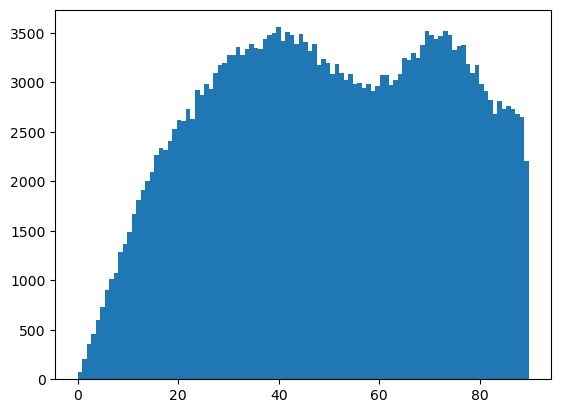

In [154]:
plt.hist(so_flare_angles[visible_both & prime_flare_mask], bins=100);
plt.show()

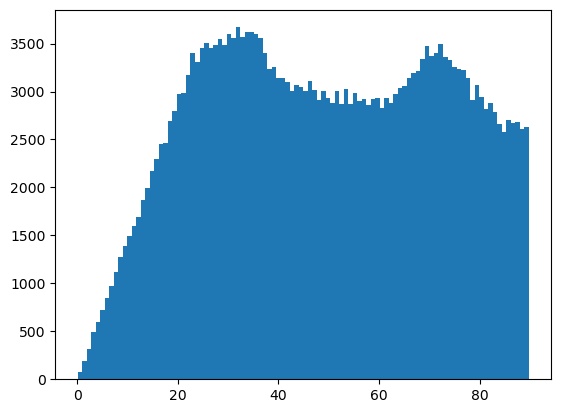

In [155]:
plt.hist(earth_flare_angles[visible_both & prime_flare_mask], bins=100);
plt.show()

In [164]:
angle_diff = earth_flare_angles - so_flare_angles

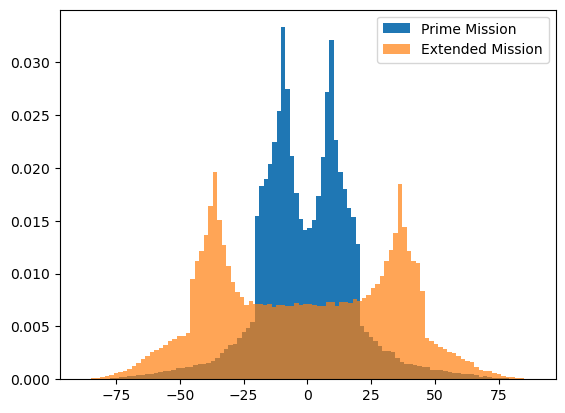

In [180]:
plt.hist(angle_diff[visible_both & prime_flare_mask], bins=100, label='Prime Mission', density=True)
plt.hist(angle_diff[visible_both & extended_flare_mask], bins=100, label='Extended Mission', alpha=0.7, density=True)
plt.legend()
plt.savefig('angle_diff_histograms.pdf')
plt.show()


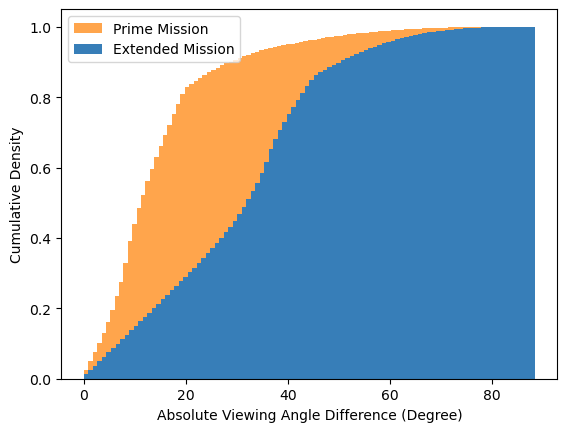

In [177]:
plt.hist(np.abs(angle_diff[visible_both & prime_flare_mask]), bins=100, label='Prime Mission', alpha=0.7, cumulative=True, density=True, color=CB_color_cycle[1]);
plt.hist(np.abs(angle_diff[visible_both & extended_flare_mask]), bins=100, label='Extended Mission', cumulative=True, density=True, color=CB_color_cycle[0]);
plt.xlabel('Absolute Viewing Angle Difference (Degree)')
plt.ylabel('Cumulative Density')
plt.legend()
plt.savefig('angle_diff_cumulative_histograms.pdf')
plt.show()

## Prime Mission

In [149]:

visible_flag = is_visible(these_flare_coords, these_so_coords, these_earth_coods)

these_flare_coords = flare_coords[visible_flag]
these_so_coords = interp_so_coords[visible_flag]
these_earth_coods = interp_earth_coords[visible_flag]

earth_angle = these_earth_coods.separation(these_flare_coords)
so_angle = these_so_coords.separation(these_flare_coords)

# remove angles that are too large for the jeffreys data
good_ind = (earth_angle < 80 * u.deg) & (so_angle < 80 * u.deg)
earth_angle = earth_angle[good_ind]
so_angle = so_angle[good_ind]

NameError: name 'is_visible' is not defined